# Fine-tune a small model with QLoRA

A parcel delivery company wants a small open model to route customer messages (Uzbek, Russian, Korean) to one of
four teams: Delivery, Payments, Claims or Account. You will load the lesson's 4-bit model, score it on the 48
held-out messages, train a small LoRA adapter on the same 163 rows with PEFT, score it again, and then serve it the
wrong way on purpose.

About 5 minutes on a free Colab CPU runtime. No GPU, account or key is needed. Run the cells from top to bottom.

**One difference from the lesson.** The lesson's run trained adapters on all 30 layers for 200 steps, on a Mac's
GPU. A free CPU is much slower, so this notebook trains adapters on the top 16 layers for 100 steps. Your scores
will be lower than the lesson's, but the pattern is the same.

## 1. Install the library versions we used

Colab already has PyTorch and Transformers. This cell pins Transformers and installs PEFT, the Hugging Face library
that adds LoRA adapters to a model. It prints nothing, or only a note about restarting, when it works. You do not
need to restart.

In [1]:
%pip install -q transformers==5.22.2 peft==0.21.3

Note: you may need to restart the kernel to use updated packages.


## 2. The data

The same rows as the lesson. A larger hosted model wrote the messages, duplicates were removed, and the rows were
split once with a fixed seed. `TRAIN` teaches the adapter, `VALID` is checked during training, and `HELD` is the
held-out set: the model never trains on it, so it is the only fair test.

**Look for:** 163 training rows, 20 validation rows, 48 held-out rows (12 per team), and training rows by language
`{'uz': 59, 'ru': 51, 'ko': 53}`.

In [2]:
SYSTEM = "You route customer messages for a parcel delivery company. Reply with one team name only: Delivery, Payments, Claims or Account."
TEAMS = ["Delivery", "Payments", "Claims", "Account"]

# (message, team): the rows the adapter learns from
TRAIN = [
    ("배송비가 왜 인상되었나요?", "Payments"),
    ("Mobil raqamimni o'zgartirmoqchiman.", "Account"),
    ("이거 문제가 있습니다. 내용물이 없습니다.", "Claims"),
    ("Paket ochilgan va ichidagi kichik buyumlar olib ketilgan.", "Claims"),
    ("Yetkazib berish narxi nima sababdan oshdi?", "Payments"),
    ("받은 물건이 부서졌어요. 이건 용납할 수 없습니다!", "Claims"),
    ("To'g'risini ayting, qachon keladi? Jahlini chiqaryapsizlar.", "Delivery"),
    ("Срочно. Повреждение.", "Claims"),
    ("Ваш сервис не работает! Вхожу уже полчаса!", "Account"),
    ("Можно изменить адрес доставки? Переехал.", "Delivery"),
    ("Xato manzil yozibman, qanday to'g'rilasa bo'ladi?", "Delivery"),
    ("다른 날짜로 배송 요청 가능한가요?", "Delivery"),
    ("Mana mening buyurtma raqamim. Ichidagi narsalar jarohatlangan.", "Claims"),
    ("아직 배송되지 않았어요. 언제쯤 받을 수 있나요?", "Delivery"),
    ("Курьер, кажется, уронил посылку, коробка помята.", "Claims"),
    ("내일로 배송일 변경 가능할까요? 일 때문에요.", "Delivery"),
    ("To'lov muvaffaqiyatsiz tugadi, boshqa urinib ko'rmoqchiman.", "Payments"),
    ("Qayta yetkazib berish sanasini belgilash mumkinmi?", "Delivery"),
    ("Nega hali yetib kelmadi? Kechiryapsizlarmi?", "Delivery"),
    ("Salom, paketim ochilgan va ichidan buyum yo'qolgan. Nima qilishim kerak?", "Claims"),
    ("Kodni qayta yuboring.", "Account"),
    ("Когда ожидать курьера? Очень неудобно.", "Delivery"),
    ("Bu nomdan foydalanish mumkin emas ekan. Boshqa nom tanlashim kerakmi?", "Account"),
    ("결제를 취소하려면 어떻게 해야 하나요?", "Payments"),
    ("Видимо, что-то случилось в пути. Есть претензия.", "Claims"),
    ("Курьер не приехал вчера. Что случилось?", "Delivery"),
    ("Почему увеличилась стоимость доставки?", "Payments"),
    ("Почему доставка задерживается? Были другие планы.", "Delivery"),
    ("Nima uchun menga buzilgan tovar yuborilgan?", "Claims"),
    ("Все еще нет. Я волнуюсь.", "Delivery"),
    ("Qutini ochib ko'rsam, tovarim yo'q edi. Kimdir olib qo'ygan shekilli.", "Claims"),
    ("제 계좌에서 왜 이렇게 많은 돈이 인출되었나요? 너무 많아요!", "Payments"),
    ("Моя электронная почта изменилась. Как обновить?", "Account"),
    ("Qaytarish qachon bo'ladi? Buyurtmani bekor qildim.", "Payments"),
    ("다른 주소로 보내주세요.", "Delivery"),
    ("비밀번호를 잊어버렸습니다.", "Account"),
    ("소포가 열려 있었고 안에 있던 작은 물건들이 사라졌습니다.", "Claims"),
    ("배송 주소를 변경할 수 있을까요? 이사했습니다.", "Delivery"),
    ("Пришлите, пожалуйста, квитанцию. Спасибо.", "Payments"),
    ("Мне вернут деньги за утерянную посылку?", "Payments"),
    ("카드 정보를 어떻게 변경할 수 있나요?", "Payments"),
    ("Bu yerda registratsiyadan o'ta olmadingizmi, yordam bera olasizmi?", "Account"),
    ("Договаривались о другой цене доставки, цена изменилась?", "Payments"),
    ("Buyurtmam qayerda ekanligini bilmoqchi edim, xabaringiz bormi?", "Delivery"),
    ("로그인 문제가 있어요.", "Account"),
    ("Mening hisobimni o'chirishni xohlayman. Qanday qilib?", "Account"),
    ("Kechirasiz, bu yerda kimdir meni ro'yxatdan o'tkazdimi?", "Account"),
    ("Xatolik yuz berdi. Yaqin kunlarda qaytarishni kutishim kerakmi?", "Payments"),
    ("Забыл пароль. Как его восстановить? Срочно нужно!", "Account"),
    ("Система пишет, что логин уже занят. Что делать?", "Account"),
    ("제 소포가 어디 있는지 알려주세요. 아직 못 받았습니다.", "Delivery"),
    ("오류가 발생했습니다. 며칠 안에 환불을 기대해도 될까요?", "Payments"),
    ("Assalomu alaykum, to'lov tasdiqlanmadi, lekin pul yechib olindi.", "Payments"),
    ("В этом месяце платежи выросли, что случилось?", "Payments"),
    ("배송비 관련해서 협의했는데, 금액이 바뀐 건가요?", "Payments"),
    ("안녕하세요, 결제가 되지 않았는데 돈이 인출되었습니다.", "Payments"),
    ("주문 번호 54321. 안의 물건이 파손되었습니다.", "Claims"),
    ("이메일 주소를 바꾸고 싶습니다.", "Account"),
    ("인증 코드가 오지 않아요.", "Account"),
    ("Yaxshi kun. Paketimni kuzatish raqamini bera olasizmi?", "Delivery"),
    ("Kelish vaqtini o'zgartira olamizmi?", "Delivery"),
    ("Manzilni o'zgartirishim kerak, iltimos.", "Delivery"),
    ("배송 주소를 변경할 수 있나요? 이사했습니다.", "Delivery"),
    ("Ожидаю сегодня. Есть какие-то проблемы?", "Delivery"),
    ("Ichida bir narsa sinib qopti, qutini ochib ko'rsam hammasi parcha-parcha.", "Claims"),
    ("Nima uchun elektron pochtam tasdiqlanmayapti? Bu juda zerikarli!", "Account"),
    ("Menga shu kunlari kerak emas edi, kechiktirib bo'ladimi?", "Delivery"),
    ("Посылка была вскрыта, и мелкие предметы внутри пропали.", "Claims"),
    ("Очень расстроен качеством доставки. Повреждено.", "Claims"),
    ("Хочу на другой адрес.", "Delivery"),
    ("Xabaringiz bor, meni pochta bo'limida kutib turgan edim. U erda menga posilka shikastlangani aytildi.", "Claims"),
    ("Tasdiqlash kodi kelmadi. Qayta yuboring. Sog' bo'ling.", "Account"),
    ("Bu juda g'alati, qutida hech narsa yo'q edi.", "Claims"),
    ("새로운 로그인 정보가 필요합니다.", "Account"),
    ("Yordam bering! Posilka.", "Claims"),
    ("Telefon raqamimni qanday o'zgartirishim mumkin? Yangi raqamimni qo'shmoqchiman.", "Account"),
    ("Когда будет возврат? Я отменил заказ.", "Payments"),
    ("Как полностью удалить мою учетную запись?", "Account"),
    ("Пришлите, пожалуйста, код для подтверждения входа.", "Account"),
    ("Что за сервис? Товары не должны доставляться в таком состоянии!", "Claims"),
    ("안녕하세요, 제가 받은 소포가 손상되었습니다. 어떻게 해야 합니까?", "Claims"),
    ("고장. 교환.", "Claims"),
    ("Kecha yetkazib berish kerak edi, hali ham yo'q.", "Delivery"),
    ("Мне нужен счет-фактура. Где я могу его получить?", "Payments"),
    ("Kirishda xatolik yuz berdi. Iltimos, tekshirib ko'ring.", "Account"),
    ("Обновите мой email.", "Account"),
    ("오늘 도착 예정인데, 혹시 문제 있나요?", "Delivery"),
    ("Kuryer paketni tashlab yuborgan ko'rinadi, qutisi ezilgan.", "Claims"),
    ("전화번호 변경하고 싶어요.", "Account"),
    ("실례합니다. 결제가 안 되었는데 얼마를 내야 하나요?", "Payments"),
    ("안녕하세요, 제 소포가 어디에 있나요? 추적 번호 12345입니다.", "Delivery"),
    ("물건이 빠져 있어요. 확인 부탁드립니다.", "Claims"),
    ("환불받아야 하는데 아직 들어오지 않았어요.", "Payments"),
    ("Из-за плохой упаковки мой товар пострадал. Верните деньги.", "Claims"),
    ("Qadoq tez orada keladimi?", "Delivery"),
    ("Kechirasiz, to'lov qilinmagan bo'lsa ham, qancha to'lanadi?", "Payments"),
    ("곧 올까요?", "Delivery"),
    ("배달원이 소포를 떨어뜨린 것 같습니다. 상자가 찌그러져 있어요.", "Claims"),
    ("Время доставки другое?", "Delivery"),
    ("Ваша служба ужасна! Где моя посылка?!", "Delivery"),
    ("환불은 언제 되나요? 주문을 취소했습니다.", "Payments"),
    ("Nima uchun mening hisobimdan buncha pul yechib olindi? Bu juda ko'p!", "Payments"),
    ("분실된 소포에 대한 환불을 받을 수 있나요?", "Payments"),
    ("Nima uchun mening tovarim shikastlangan? Buning uchun kim javob beradi?", "Claims"),
    ("Mening eski elektron pochtam endi ishlamaydi. Unga kirishim kerak.", "Account"),
    ("Salom, paketim qayerda ekanligini bilmoqchiman? 5-oyda jo'natilgan edi.", "Delivery"),
    ("Здравствуйте, посылка пришла поврежденной. Что делать?", "Claims"),
    ("택배 개봉했는데 물건이 부서져 있었어요.", "Claims"),
    ("Нужен счет-фактура. Когда сможете отправить?", "Payments"),
    ("오늘 배송되나요? 알려주세요.", "Delivery"),
    ("Bugunmi yetkazib berish? Yoki kelasi hafta?", "Delivery"),
    ("안녕하세요, 제 소포가 손상된 채로 도착했습니다. 어떻게 해야 하나요?", "Claims"),
    ("Улица Ленина, дом 10, квартира 5. Новый адрес.", "Delivery"),
    ("계정 삭제는 어떻게 하나요?", "Account"),
    ("Открыл посылку, а моего товара там нет. Кто-то украл?", "Claims"),
    ("결제가 실패했어요. 다시 시도하고 싶어요.", "Payments"),
    ("Не приходит SMS с кодом подтверждения.", "Account"),
    ("안에 뭔가 깨졌어요. 상자를 열어보니 다 부서져 있었습니다.", "Claims"),
    ("오늘 언제쯤 도착할까요? 기다리고 있습니다.", "Delivery"),
    ("Коробка была вскрыта, и внутри не оказалось всех предметов.", "Claims"),
    ("Menga kelgan buyurtma boshqa bir odamga tegishli ekanligini tekshirib ko'ring.", "Claims"),
    ("안녕하세요, 카드에서 이중으로 요금이 청구되었습니다. 확인 부탁드립니다.", "Payments"),
    ("배송비가 너무 비싼 것 같아요. 실제 요금은 얼마인가요?", "Payments"),
    ("Kartamdan ikki marta pul yechib olindi, iltimos tekshirib bering.", "Payments"),
    ("Меня заблокировали? Почему я не могу зайти?", "Account"),
    ("소포를 열었는데 물건이 없었습니다. 누가 가져간 걸까요?", "Claims"),
    ("Salom, paketim shikastlangan holda yetib keldi. Nima qilishim kerak?", "Claims"),
    ("세금계산서가 필요합니다. 어디서 받을 수 있나요?", "Payments"),
    ("부서진 상품이 도착했습니다. 환불 가능한가요?", "Claims"),
    ("Можно перенести на завтра? Работаю.", "Delivery"),
    ("Hisobimni himoya qilish uchun qo'shimcha chora-tadbirlar bormi?", "Account"),
    ("서울시 강남구 테헤란로 123번지 45동 6호로 부탁드립니다.", "Delivery"),
    ("Добрый день, оплата не прошла, но деньги списались.", "Payments"),
    ("Yangi manzilga jo'natish kerak.", "Delivery"),
    ("Assalomu alaykum. Pochta xodimi posilkani yomg'irda olib kelgan, endi u ho'l.", "Claims"),
    ("Salom, iltimos menga yordam bering, hisobimga kira olmayapman. Parolimni unutib qo'ydim.", "Account"),
    ("Почему мой товар поврежден? Кто за это отвечает?", "Claims"),
    ("Faktura kerak edi. Qayerdan olsam bo'ladi?", "Payments"),
    ("Kirishda muammo bor, parol ishlamayapti.", "Account"),
    ("Menga yetkazib berishda muammo bor. Shikoyatim bor.", "Claims"),
    ("어제 기사님이 오지 않으셨어요. 무슨 일인가요?", "Delivery"),
    ("Хочу удалить свой аккаунт. Как это сделать?", "Account"),
    ("Требуется изменить данные для входа.", "Account"),
    ("Почему с моего счета сняли так много денег? Это слишком много!", "Payments"),
    ("Tashakkur, lekin hali ham yetib kelmadi.", "Delivery"),
    ("Sifatsiz qadoqlash tufayli tovarim zarar ko'rdi. Pulni qaytaring.", "Claims"),
    ("아직 도착하지 않았어요. 걱정되네요.", "Delivery"),
    ("포장이 부실해서 제 물건이 손상되었습니다. 환불해주세요.", "Claims"),
    ("Yetkazib berish narxi qimmatdek tuyuldi, haqiqiy narx qancha?", "Payments"),
    ("Mening buyurtmam ho'l bo'lib keldi, ichidagi mahsulotlar yaroqsiz holga kelgan.", "Claims"),
    ("Произошла ошибка. Мне ожидать возврата в ближайшие дни?", "Payments"),
    ("Забыли пароль, как восстановить?", "Account"),
    ("정말 짜증 나네요! 왜 이렇게 복잡한 건가요?", "Account"),
    ("Платеж не прошел, хочу попробовать еще раз.", "Payments"),
    ("Menga yuborilgan narsa buzilgan. Bu qabul qilib bo'lmaydigan holat!", "Claims"),
    ("Здравствуйте, моя посылка пришла поврежденной. Что мне делать?", "Claims"),
    ("Karta ma'lumotlarimni qanday o'zgartirish mumkin?", "Payments"),
    ("Здравствуйте, где моя посылка? Трек-номер 12345.", "Delivery"),
    ("Как можно отменить оплату?", "Payments"),
    ("코드 다시 보내주세요.", "Account"),
    ("Нужно сменить номер телефона в профиле. Подскажите, как?", "Account"),
    ("Yetkazib berish haqida kelishib olgandik, narx o'zgargan?", "Payments"),
    ("Подскажите, пожалуйста, почту для входа.", "Account"),
]
# (message, team): checked during training, never trained on
VALID = [
    ("Посылка пришла, но она не в том виде, что я ожидал.", "Claims"),
    ("이게 무슨 서비스인가요? 물건이 이런 상태로 배달되면 안 됩니다!", "Claims"),
    ("Salom, kartamdan ikki marta pul yechib olindi. Iltimos tekshirib bering.", "Payments"),
    ("Можно изменить адрес доставки? Переехал на днях.", "Delivery"),
    ("Здравствуйте, с моей карты сняли деньги дважды. Пожалуйста, проверьте.", "Payments"),
    ("배송이 왜 늦어지나요? 약속이 있었는데.", "Delivery"),
    ("Скоро будет?", "Delivery"),
    ("Когда будет доставка? Сообщите, пожалуйста.", "Delivery"),
    ("Pulim qaytarilishi kerak edi, hali ham kelmadi.", "Payments"),
    ("Qanday qilib to'lovni bekor qilish mumkin?", "Payments"),
    ("Yo'qotilgan paket uchun pul qaytarib beriladimi?", "Payments"),
    ("Qutini ochganimda, undagi mahsulot sindirilgan edi.", "Claims"),
    ("Manzilni o'zgartirishim kerak, iltimos. Ertaga yetkazib berish kerak edi.", "Delivery"),
    ("Bu qanday xizmat? Tovarlar bunday holatda yetkazib berilmasligi kerak!", "Claims"),
    ("카드에서 이중으로 출금되었습니다. 확인 부탁드립니다.", "Payments"),
    ("С карты списали дважды, проверьте, пожалуйста.", "Payments"),
    ("Tashakkur, pulim qaytdi. Yaxshi ish.", "Payments"),
    ("Почему до сих пор не доставили? Очень жду!", "Delivery"),
    ("Kodni yuboring! Tezroq! Men kutib o'tirishga vaqtim yo'q.", "Account"),
    ("계정 설정 좀 업데이트해야 해요.", "Account"),
]
# (language, team, message): the held-out set, kept aside for the final score
HELD = [
    ("ru", "Account", "Не проходит авторизация, помогите разобраться."),
    ("ru", "Claims", "Моя посылка промокла под дождем. Можно ли что-то сделать?"),
    ("ko", "Payments", "이번 달 요금이 좀 많이 나왔네요. 무슨 일이죠?"),
    ("ko", "Payments", "감사합니다, 돈이 환불되었어요. 잘 처리되었습니다."),
    ("ko", "Account", "여기 등록된 적이 있는지 확인 부탁드립니다."),
    ("ko", "Delivery", "정말 최악이네요! 제 소포는 어디에 있습니까?!"),
    ("uz", "Payments", "Chekni yuboring, iltimos. Tashakkur."),
    ("ru", "Claims", "Добрый день. При вскрытии обнаружил, что товар сломан."),
    ("ko", "Delivery", "소포 언제 와요?"),
    ("ko", "Claims", "소포가 열려 있었고 내용물이 분실되었습니다."),
    ("ru", "Account", "Нужно сменить номер телефона в настройках."),
    ("ru", "Claims", "Что-то внутри разбилось, когда я открыл коробку, всё в крошках."),
    ("ru", "Claims", "Заказ номер 12345. Товары внутри разбиты."),
    ("ru", "Payments", "Извините, если оплата не прошла, сколько я должен?"),
    ("uz", "Account", "Tasdiqlash kodi kelmayapti, tekshirib bering."),
    ("uz", "Account", "Elektron pochta manzilimni yangilash kerak."),
    ("ru", "Delivery", "Возможна ли другая дата доставки?"),
    ("uz", "Payments", "Bu oyda to'lovlar ko'payib ketdi, nima bo'ldi?"),
    ("ru", "Delivery", "Подскажите, где моя посылка? Третий день жду."),
    ("ru", "Account", "Не могу войти в свой профиль."),
    ("ru", "Delivery", "Где посылка?"),
    ("ru", "Account", "Пришло сообщение с кодом, но я ничего не запрашивал."),
    ("ru", "Claims", "Не хватает частей из посылки. Прошу разобраться."),
    ("ru", "Claims", "Мой заказ пришел мокрый, содержимое испорчено."),
    ("ru", "Payments", "Мне должны были вернуть деньги, но их нет."),
    ("ru", "Payments", "Как изменить данные моей карты?"),
    ("ko", "Payments", "영수증 좀 보내주세요. 감사합니다."),
    ("ko", "Claims", "제 주문이 젖어서 왔어요. 내용물이 망가졌습니다."),
    ("uz", "Account", "Parolimni unutdim, nima qilishim kerak?"),
    ("ru", "Claims", "Мне привезли сломанную вещь. Это неприемлемо!"),
    ("ko", "Payments", "세금계산서가 필요합니다. 언제 보내주실 수 있나요?"),
    ("ru", "Account", "Почему не приходит код подтверждения? Уже третий раз пытаюсь."),
    ("ko", "Claims", "택배가 젖어서 안의 내용물이 망가졌어요."),
    ("uz", "Payments", "Menga hisob-faktura kerak, qachon yuborasiz?"),
    ("ko", "Delivery", "추적해보니 저희 도시에 있다는데, 언제 가져다주나요?"),
    ("uz", "Delivery", "Bugun qachon keladi shu pochta?"),
    ("ko", "Claims", "제 물건이 왜 손상된 거죠? 누가 책임지나요?"),
    ("ko", "Delivery", "배송 시간 변경 가능합니까?"),
    ("uz", "Account", "Akkauntni qanday o'chirib tashlash mumkin?"),
    ("ko", "Claims", "비에 젖은 택배를 받았습니다. 도와주세요."),
    ("ru", "Delivery", "Отслеживание посылки показывает, что она в городе. Когда привезут?"),
    ("uz", "Account", "Mening shaxsiy ma'lumotlarimni yangilash kerak, iltimos."),
    ("ru", "Payments", "Стоимость доставки кажется завышенной. Какая реальная цена?"),
    ("uz", "Delivery", "Oybek ko'chasi, 15-uyga olib kelishingizni so'rayman."),
    ("uz", "Delivery", "Paketimning holati qanday? O'ta muhim."),
    ("uz", "Delivery", "Hali ham kutmoqdamiz."),
    ("ru", "Payments", "Спасибо, деньги вернули. Отличная работа."),
    ("ru", "Account", "Здравствуйте, не могу войти в свой аккаунт. Помогите, пожалуйста."),
]

import re
def lang_of(text):  # the script tells the language apart in this data
    if re.search("[\uac00-\ud7a3]", text): return "ko"
    if re.search("[\u0400-\u04ff]", text): return "ru"
    return "uz"

print("train", len(TRAIN), "valid", len(VALID), "held-out", len(HELD))
for t in TEAMS:
    print(f"{t:9} train {sum(team == t for _, team in TRAIN):3}   held-out {sum(team == t for _, team, _ in HELD)}")
print("training rows by language:", {l: sum(lang_of(m) == l for m, _ in TRAIN) for l in ["uz", "ru", "ko"]})

train 163 valid 20 held-out 48
Delivery  train  42   held-out 12
Payments  train  40   held-out 12
Claims    train  44   held-out 12
Account   train  37   held-out 12
training rows by language: {'uz': 59, 'ru': 51, 'ko': 53}


## 3. A model stored in 4 bits

The lesson's model is SmolLM2-135M-Instruct in a 4-bit file made for MLX, Apple's library. Each weight is stored as
a 4-bit code, a whole number from 0 to 15. Each group of 64 weights also has one `scale` and one `bias`, and the
real weight is `code * scale + bias`. The cell downloads the file (76 MB) and unpacks one group.

**Look for:** the file is 76 MB, while the same 134.5 million weights as 32-bit floats would take about 540 MB.
The first 8 codes are small whole numbers, and a group of 64 weights has at most 16 different values (here 13).
That is the precision QLoRA keeps the frozen model in.

In [3]:
import os, json, copy, time, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
import numpy as np, torch
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

REPO = "Irfanuruchi/SmolLM2-135M-Instruct-MLX-4bit"   # the lesson's model, 4-bit MLX format
path = hf_hub_download(REPO, "model.safetensors")
packed = load_file(path)
print("file size:", round(os.path.getsize(path) / 1e6), "MB")

name = "model.layers.0.self_attn.q_proj"   # one weight matrix, 576 x 576
words = packed[name + ".weight"]
print("stored as:", words.dtype, tuple(words.shape), "-> 8 four-bit codes in each 32-bit word")
print("scales:", tuple(packed[name + ".scales"].shape), " biases:", tuple(packed[name + ".biases"].shape), "(one per group of 64 weights)")

def unpack(name):
    """4-bit codes -> float weights: weight = code * scale + bias, per group of 64."""
    w = packed[name + ".weight"].view(torch.int32)
    codes = (w.unsqueeze(-1) >> torch.arange(0, 32, 4, dtype=torch.int32)) & 0xF
    codes = codes.reshape(w.shape[0], -1, 64).float()
    scale = packed[name + ".scales"].float().unsqueeze(-1)
    bias = packed[name + ".biases"].float().unsqueeze(-1)
    return (codes * scale + bias).reshape(w.shape[0], -1), codes

weights, codes = unpack(name)
print("first 8 codes:  ", codes[0, 0, :8].int().tolist())
print("first 8 weights:", [round(x, 4) for x in weights[0, :8].tolist()])
print("different values in this group of 64:", len(set(weights[0, :64].tolist())))

file size: 76 MB
stored as: torch.uint32 (576, 72) -> 8 four-bit codes in each 32-bit word
scales: (576, 9)  biases: (576, 9) (one per group of 64 weights)
first 8 codes:   [10, 8, 10, 15, 0, 10, 8, 4]
first 8 weights: [-0.127, 0.1328, -0.127, -0.7764, 1.1719, -0.127, 0.1328, 0.6523]
different values in this group of 64: 13


## 4. Build the model from the 4-bit file

PyTorch on a CPU has no fast 4-bit math, so the cell unpacks every 4-bit weight into a normal float once and loads
the result into a Hugging Face `LlamaForCausalLM` (the model type SmolLM2 uses). The numbers are exactly the 4-bit
model's numbers; they just take more memory now. On a GPU, the bitsandbytes library keeps them in 4 bits in memory
too, as on the lesson's screen 7.

**Look for:** 30 layers and 134,515,008 parameters, the 134.515M in the lesson's training log.

In [4]:
from transformers import AutoTokenizer, LlamaConfig, LlamaForCausalLM, LlamaModel

cfg = json.load(open(hf_hub_download(REPO, "config.json")))
cfg.pop("quantization"); cfg.pop("quantization_config")   # we unpack the 4 bits ourselves
config = LlamaConfig(**cfg)

state = {}
for key, tensor in packed.items():
    if key.endswith(".weight") and tensor.dtype == torch.uint32:
        state[key] = unpack(key[:-len(".weight")])[0]
    elif key.endswith(".weight"):
        state[key] = tensor.float()

torch.manual_seed(0)
model = LlamaForCausalLM(config).float()
model.load_state_dict(state, strict=False)
model.tie_weights()
model.eval()
tokenizer = AutoTokenizer.from_pretrained(REPO)
tokenizer.padding_side = "left"
print("layers:", config.num_hidden_layers)
print("parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

layers: 30
parameters: 134,515,008


## 5. The chat template

`chat_prompt` builds the prompt the way the lesson's evaluation did: the system message and the customer's message
go through the tokenizer's chat template, with `add_generation_prompt=True`. `generate_all` asks the model for a
greedy reply, cut after 12 tokens, and `score` counts clean labels (exactly one of the four team names) and right
teams.

**Look for:** the template the lesson shows on screen 8: a system turn, a user turn, each closed by `<|im_end|>`, and
an open `<|im_start|>assistant` line at the end, where the model starts writing.

In [5]:
def chat_prompt(message):   # what evaluate.py and the fixed route() build
    chat = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": message}]
    return tokenizer.apply_chat_template(chat, add_generation_prompt=True, tokenize=False)

@torch.no_grad()
def generate_all(m, prompts, max_new_tokens=12):
    """Greedy replies, cut after max_new_tokens tokens, 16 prompts at a time."""
    m.eval()
    out = []
    for k in range(0, len(prompts), 16):
        enc = tokenizer(prompts[k:k + 16], return_tensors="pt", padding=True, add_special_tokens=False)
        ids = m.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                         eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.eos_token_id)
        out += [tokenizer.decode(r, skip_special_tokens=True).strip() for r in ids[:, enc.input_ids.shape[1]:]]
    return out

def score(answers, rows):
    right = sum(a == team for a, (_, team, _) in zip(answers, rows))
    clean = sum(a in TEAMS for a in answers)
    return right, clean

print(chat_prompt(HELD[0][2]))

<|im_start|>system
You route customer messages for a parcel delivery company. Reply with one team name only: Delivery, Payments, Claims or Account.<|im_end|>
<|im_start|>user
Не проходит авторизация, помогите разобраться.<|im_end|>
<|im_start|>assistant



## 6. Before training: the base model

The eight messages from the lesson's screens 2 and 4, then the score on all 48 held-out messages.

**Look for:** not one team name. The model copies the start of the message back (`'소포 언제'`, `'Где посылка?'`),
writes English small talk to the Uzbek messages, or writes broken words. The score is **clean label 0, right team
0**, as in the lesson. Some replies differ a little from the lesson's, because a CPU rounds numbers differently from
the Mac's GPU.

In [6]:
PICK = [0, 3, 12, 8, 6, 20, 28, 39]   # the eight messages of the lesson's screens 2 and 4

base_answers = generate_all(model, [chat_prompt(m) for _, _, m in HELD])
for i in PICK:
    lang, team, message = HELD[i]
    print(f"{team:9}| {message}")
    print(f"{'':9}| base: {base_answers[i]!r}")
right, clean = score(base_answers, HELD)
print(f"\nbase model, all {len(HELD)} held-out messages: clean label {clean}, right team {right}")

Account  | Не проходит авторизация, помогите разобраться.
         | base: 'Мой раза очения.'
Payments | 감사합니다, 돈이 환불되었어요. 잘 처리되었습니다.
         | base: '안녕믉운'
Claims   | Заказ номер 12345. Товары внутри разбиты.
         | base: 'Мой точевевари'
Delivery | 소포 언제 와요?
         | base: '소포 언제'
Payments | Chekni yuboring, iltimos. Tashakkur.
         | base: "I'm glad you liked the response. I'll keep you"
Delivery | Где посылка?
         | base: 'Где посылка?'
Account  | Parolimni unutdim, nima qilishim kerak?
         | base: "I'm sorry for the confusion. I'm a customer service"
Claims   | 비에 젖은 택배를 받았습니다. 도와주세요.
         | base: '안녕반 안'

base model, all 48 held-out messages: clean label 0, right team 0


## 7. Add the LoRA adapter

`LoraConfig` sets up the adapter: rank `r=8` and the seven linear layers of each block, as in the lesson's run.
`lora_alpha=160` makes the adapter's scale 160 / 8 = 20, mlx-lm's default. `layers_to_transform` puts adapters on
layers 14 to 29 only (the lesson used all 30). `get_peft_model` freezes every original weight and adds the small
trainable matrices next to them.

**Look for:** `trainable params: 1,302,528`, under 1% of the model (0.9590%). The lesson's run, with adapters on all
30 layers, trained 2.442M (1.816%). `all params` here also counts the adapter.

In [7]:
from peft import LoraConfig, get_peft_model

FIRST = 14   # adapters on layers 14 to 29: the top 16 of 30 (mlx-lm's default)
lora = LoraConfig(r=8, lora_alpha=160, lora_dropout=0.0,   # rank 8; scale 160 / 8 = 20, as in mlx-lm
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
                  layers_to_transform=list(range(FIRST, config.num_hidden_layers)), task_type="CAUSAL_LM")
torch.manual_seed(0)
tuned = get_peft_model(model, lora)
tuned.print_trainable_parameters()

trainable params: 1,302,528 || all params: 135,817,536 || trainable%: 0.9590


## 8. Training rows, and a shortcut for the CPU

Each training row is a full chat: system message, customer message, and the team name as the assistant's reply.
`encode` returns the tokens and how many belong to the prompt, so the loss can count only the reply. That is
`--mask-prompt` in the lesson's command.

The shortcut: layers 0 to 13 have no adapter, so for a given row their output is always the same. The cell runs
them once for every row and keeps the result; training then only runs layers 14 to 29 (`top`). The layers are the
same objects as in `tuned`, so training `top` trains the adapter inside `tuned`.

**Look for:** 79 tokens in the first row, of which only 4 count for the loss: `['Pay', 'ments', '<|im_end|>',
'Ċ']`. The model learns to write the team name and then the end-of-turn marker (`Ċ` is a newline).

In [8]:
def encode(message, team):
    chat = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": message},
            {"role": "assistant", "content": team}]
    full = tokenizer.apply_chat_template(chat, tokenize=False)
    prompt = tokenizer.apply_chat_template(chat[:2], add_generation_prompt=True, tokenize=False)
    ids = tokenizer(full, add_special_tokens=False).input_ids
    n_prompt = len(tokenizer(prompt, add_special_tokens=False).input_ids)
    return ids, n_prompt   # the loss counts only ids[n_prompt:], the reply (like --mask-prompt)

ids, n_prompt = encode(*TRAIN[0])
print("tokens in the first row:", len(ids), "  prompt (no loss):", n_prompt, "  reply (loss):", len(ids) - n_prompt)
print("reply tokens:", tokenizer.convert_ids_to_tokens(ids[n_prompt:]))

inner = tuned.base_model.model.model
def part(layers, norm):   # a model that runs only some of the layers (the same layer objects)
    c = copy.deepcopy(config); c.num_hidden_layers = len(layers); c.vocab_size = 1; c.pad_token_id = None
    p = LlamaModel(c); p.layers = layers; p.norm = norm; p.rotary_emb = inner.rotary_emb
    return p
bottom = part(inner.layers[:FIRST], torch.nn.Identity()); bottom.embed_tokens = inner.embed_tokens
top = part(inner.layers[FIRST:], inner.norm)

@torch.no_grad()
def run_bottom(rows):   # layers 0-13 have no adapter, so their output never changes: compute it once
    bottom.eval()
    out = []
    for k in range(0, len(rows), 16):
        enc = [encode(m, t) for m, t in rows[k:k + 16]]
        L = max(len(i) for i, _ in enc)
        x = torch.full((len(enc), L), tokenizer.eos_token_id); att = torch.zeros_like(x)
        for r, (i, _) in enumerate(enc):
            x[r, :len(i)] = torch.tensor(i); att[r, :len(i)] = 1
        h = bottom(input_ids=x, attention_mask=att, use_cache=False).last_hidden_state
        out += [(h[r, :len(i)], i, n) for r, (i, n) in enumerate(enc)]
    return out

t0 = time.time()
train_rows, valid_rows = run_bottom(TRAIN), run_bottom(VALID)
print(f"layers 0-{FIRST - 1} run once for {len(train_rows) + len(valid_rows)} rows in {time.time() - t0:.0f} s")

tokens in the first row: 79   prompt (no loss): 75   reply (loss): 4
reply tokens: ['Pay', 'ments', '<|im_end|>', 'Ċ']


layers 0-13 run once for 183 rows in 9 s


## 9. Train

100 steps of 4 rows, learning rate 1e-4, the Adam optimizer: the lesson's settings, with half the steps. Every 10
steps the cell prints the mean training loss, and every 20 steps the loss on the 20 validation rows. This takes
about 1 to 3 minutes on a free Colab CPU.

**Look for:** the validation loss starts at 4.951. The training loss falls fast at first (2.150 at step 10, 0.712
at step 20), then slowly, to 0.369 at step 100. After step 20 the validation loss stays in a band (0.378 to 0.466
in our run) instead of falling with it. In the plot, the training line keeps sinking slowly while the validation
dots go up and down.

step   1  val 4.951


step  10  train 2.150


step  20  train 0.712


step  20  val 0.611


step  30  train 0.542


step  40  train 0.458


... (6 outputs left out)

step  80  val 0.466


step  90  train 0.376


step 100  train 0.369


step 100  val 0.399
100 steps in 88 s


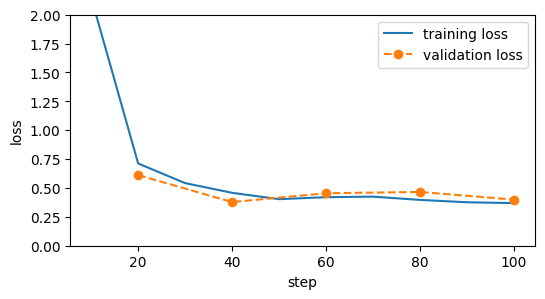

In [9]:
import matplotlib.pyplot as plt

ITERS, BATCH, LR = 100, 4, 1e-4

def loss_on(rows):
    """Mean cross-entropy on the reply tokens only, through layers 14-29 (with adapters) and the output layer."""
    L = max(len(i) for _, i, _ in rows)
    h = torch.zeros(len(rows), L, config.hidden_size); att = torch.zeros(len(rows), L, dtype=torch.long)
    for r, (hh, i, _) in enumerate(rows):
        h[r, :len(i)] = hh; att[r, :len(i)] = 1
    out = top(inputs_embeds=h, attention_mask=att, use_cache=False).last_hidden_state
    where = [(r, p) for r, (_, i, n) in enumerate(rows) for p in range(n - 1, len(i) - 1)]
    target = torch.tensor([rows[r][1][p + 1] for r, p in where])
    logits = tuned.base_model.model.lm_head(out[[r for r, _ in where], [p for _, p in where]])
    return torch.nn.functional.cross_entropy(logits, target), len(where)

@torch.no_grad()
def valid_loss():
    top.eval(); total = count = 0
    for k in range(0, len(valid_rows), BATCH):
        loss, n = loss_on(valid_rows[k:k + BATCH]); total += loss.item() * n; count += n
    return total / count

order = sorted(range(len(train_rows)), key=lambda i: len(train_rows[i][1]))   # similar lengths together
batches = [order[i:i + BATCH] for i in range(0, len(order) - BATCH + 1, BATCH)]
rng = np.random.default_rng(0)
optimizer = torch.optim.Adam([p for p in tuned.parameters() if p.requires_grad], lr=LR)

train_log, val_log = [], [(1, valid_loss())]
print(f"step   1  val {val_log[0][1]:.3f}")
step, recent, t0 = 0, [], time.time()
while step < ITERS:
    for b in rng.permutation(len(batches)):
        if step == ITERS: break
        top.train(); step += 1
        loss, _ = loss_on([train_rows[i] for i in batches[b]])
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        recent.append(loss.item())
        if step % 10 == 0:
            train_log.append((step, np.mean(recent))); recent = []
            print(f"step {step:3}  train {train_log[-1][1]:.3f}")
        if step % 20 == 0:
            val_log.append((step, valid_loss()))
            print(f"step {step:3}  val {val_log[-1][1]:.3f}")
print(f"{ITERS} steps in {time.time() - t0:.0f} s")

plt.figure(figsize=(6, 3))
plt.plot(*zip(*train_log), label="training loss")
plt.plot(*zip(*val_log[1:]), "o--", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.ylim(0, 2); plt.legend(); plt.show()

## 10. After training: the held-out set

The same 48 messages, the same prompt, now through the tuned model.

**Look for:** **clean label 48** of 48: every reply is a team name. Our run got **22 right**, against 0 for the base
model (picking at random gets about 12). The misses bunch up: Uzbek is the weakest language (5 of 12 in our run),
and the model says Delivery far more often (25 times) than Delivery messages appear (12). That is the same pattern
as the lesson's screen 5. It is better than the base model, but not ready to route alone.

In [10]:
tuned_answers = generate_all(tuned, [chat_prompt(m) for _, _, m in HELD])
for i in PICK:
    print(f"{HELD[i][1]:9}| tuned: {tuned_answers[i]!r}")
right, clean = score(tuned_answers, HELD)
print(f"\ntuned model, all {len(HELD)} held-out messages: clean label {clean}, right team {right}")
print("(base model: clean label", score(base_answers, HELD)[1], "right team", score(base_answers, HELD)[0], ")")

print("\nby language:")
for l in ["uz", "ru", "ko"]:
    rows = [k for k, h in enumerate(HELD) if h[0] == l]
    print(f"  {l}  {sum(tuned_answers[k] == HELD[k][1] for k in rows):2} of {len(rows)} right")
print("by team:                     times it said this team")
for t in TEAMS:
    rows = [k for k, h in enumerate(HELD) if h[1] == t]
    said = sum(a == t for a in tuned_answers)
    print(f"  {t:9} {sum(tuned_answers[k] == t for k in rows):2} of {len(rows)} right   {said:2}")

Account  | tuned: 'Account'
Payments | tuned: 'Delivery'
Claims   | tuned: 'Account'
Delivery | tuned: 'Delivery'
Payments | tuned: 'Account'
Delivery | tuned: 'Delivery'
Account  | tuned: 'Delivery'
Claims   | tuned: 'Account'

tuned model, all 48 held-out messages: clean label 48, right team 22
(base model: clean label 0 right team 0 )

by language:
  uz   5 of 12 right
  ru  11 of 22 right
  ko   6 of 14 right
by team:                     times it said this team
  Delivery  10 of 12 right   25
  Payments   2 of 12 right    6
  Claims     5 of 12 right    5
  Account    5 of 12 right   12


## 11. Broken on purpose: served without the chat template

This is the server's `route_broken` from the lesson: the prompt is glued by hand as plain text. Same tuned model,
same 12-token limit. Nothing raises an error.

**Look for:** every reply starts with a team name, but it does not stop: it goes on with more names
(`'Account Account Delivery Delivery ...'`). So **clean label 0**, right team 0. The model learned to write the
name right after an open assistant turn and then stop with `<|im_end|>`; here it never sees that pattern. In the
lesson's run the damage was smaller (42 clean labels), but the cause and the fix are the same: build the serving
prompt with `apply_chat_template`.

In [11]:
def plain_prompt(message):   # route_broken() in route_compare.py: glued by hand, no chat template
    return SYSTEM + "\n" + message + "\n"

broken_answers = generate_all(tuned, [plain_prompt(m) for _, _, m in HELD])
for i in PICK[:4]:
    print(f"{HELD[i][1]:9}| served by hand: {broken_answers[i]!r}")
right, clean = score(broken_answers, HELD)
print(f"\nsame tuned model, plain-text prompt: clean label {clean}, right team {right}")
print("with the chat template:            clean label", score(tuned_answers, HELD)[1], "right team", score(tuned_answers, HELD)[0])

Account  | served by hand: 'Account\nPayments\nClaims\nClaims'
Payments | served by hand: 'Account Account Delivery Delivery Delivery Delivery Delivery Delivery Delivery Delivery Delivery Delivery'
Claims   | served by hand: 'Account\nPayments\nClaims\nClaims'
Delivery | served by hand: 'Account\nAccount\nAccount\nAccount\nAccount\nAccount'

same tuned model, plain-text prompt: clean label 0, right team 0
with the chat template:            clean label 48 right team 22


## Now change it

Each cell below has one line marked `# <- change this`. Edit it, run the cell, and compare.

### Experiment 1: your own message

The cell routes one message three ways: the tuned model with the template, the tuned model with the plain prompt,
and the base model (`disable_adapter()` switches the adapter off for a moment).

**What should change:** write any short message about a parcel, a payment, damage or a login, in Uzbek, Russian or
Korean. The template route answers with one team name. The plain route runs on with several names. The base model
does not answer with a team name at all.

In [12]:
message = "Mening posilkam qachon keladi?"   # <- change this: any customer message

print("route (template):  ", generate_all(tuned, [chat_prompt(message)])[0])
print("route_broken (plain):", generate_all(tuned, [plain_prompt(message)])[0])
with tuned.disable_adapter():
    print("base model (template):", generate_all(tuned, [chat_prompt(message)])[0])

route (template):   Delivery


route_broken (plain): Account Account
Delivery Delivery
Payments Delivery
Account Delivery


base model (template): I'm sorry for the confusion. I'm a customer service


### Experiment 2: give the broken route more room

The lesson asked whether raising `max_tokens` would fix the broken route. The cell runs it on the first 12 held-out
messages.

**What should change:** with 30, the clean-label count stays at 0 and the longest reply gets longer. The model does
not stop on its own without the template, so more room only gives more junk.

In [13]:
max_tokens = 12   # <- change this: try 30

some = HELD[:12]
answers = generate_all(tuned, [plain_prompt(m) for _, _, m in some], max_new_tokens=max_tokens)
right, clean = score(answers, some)
print(f"plain prompt, max {max_tokens} tokens: clean label {clean} of {len(some)}, right team {right}")
print("longest reply:", max(answers, key=len)[:120])

plain prompt, max 12 tokens: clean label 0 of 12, right team 0
longest reply: Account Account Delivery Delivery Delivery Delivery Delivery Delivery Delivery Delivery Delivery Delivery


### Experiment 3: switch the adapter off

The tuned model is the same frozen model plus the adapter. The cell checks that one frozen weight is still exactly
the unpacked 4-bit weight from step 4, then scores the first 12 held-out messages.

**What should change:** the first line prints `True` either way: training never touched the 4-bit weights. With
`False`, the adapter is switched off and the clean-label count drops to 0, like the base model in step 6. All of
the change lives in the 1.3 million adapter numbers.

In [14]:
use_adapter = True   # <- change this to False

frozen = inner.layers[20].self_attn.q_proj.base_layer.weight
print("frozen weight still equal to the 4-bit file:", torch.equal(frozen, unpack("model.layers.20.self_attn.q_proj")[0]))
some = HELD[:12]
prompts = [chat_prompt(m) for _, _, m in some]
if use_adapter:
    answers = generate_all(tuned, prompts)
else:
    with tuned.disable_adapter():
        answers = generate_all(tuned, prompts)
right, clean = score(answers, some)
print(f"adapter {'on' if use_adapter else 'off'}: clean label {clean} of {len(some)}, right team {right}")
print("first three replies:", answers[:3])

frozen weight still equal to the 4-bit file: True


adapter on: clean label 12 of 12, right team 6
first three replies: ['Account', 'Account', 'Delivery']


## What you should see

- Before training, the base model's replies are not team names: clean label 0 of 48 held-out messages (step 6).
- `print_trainable_parameters()` shows the adapter as a small share of the model: 1,302,528 trainable numbers,
  0.9590% (step 7). The lesson's run, with adapters on all 30 layers, trained 2.442M (1.816%).
- The training loss, printed every 10 steps, falls fast at first, then slowly: 2.150 at step 10, 0.712 at step 20,
  0.369 at step 100 (step 9).
- After training, every reply on the held-out set is one of the four team names: clean label 48 of 48 (step 10).
- The tuned model gets more held-out messages right than the base model (22 against 0 in our run), and Uzbek is the
  weakest language (step 10).
- Served without the chat template, the same tuned model gives clean label 0: the replies run on past the team name
  (step 11).

Your numbers can differ a little from ours on another CPU; the pattern should not. Keep this notebook: the router is
your fine-tuning portfolio project, served in stage 6 and finished in stage 7.